# Plot nominal satellite tracks

This example loads nominal tracks bundled with SatPass, selects the tracks crossing a geographic domain, and plots them.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

SatPass version: 0.1.0


## Select a mission and geographic domain

The domain format is `[longitude_min, longitude_max, latitude_min, latitude_max]` in degrees.

In [2]:
mission = "sw" 
domain = [140.0, 150.0, -45.0, -35.0]

domain = [100.0, 150.0, -70.0, -30.0]

## Load and select nominal tracks

In [4]:
nominal = satpass.NominalTrack(mission)
tracks = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

print(f"Mission: {nominal.meta['full_name']}")
print(f"Total nominal points: {len(nominal.nominal):,}")
print(f"Selected tracks: {tracks['track'].nunique()}")
print(f"Selected points: {len(tracks):,}")

tracks.head()

Mission: SWOT
Total nominal points: 1,803,264
Selected tracks: 124
Selected points: 60,448


,track,lon,lat,lon0_360,subcycle,direction
11331,4,146.402211,-30.025929,148.070208,2.0,des
11332,4,146.414649,-30.082540,148.070208,2.0,des
11333,4,146.427102,-30.139151,148.070208,2.0,des
11334,4,146.439615,-30.195745,148.070208,2.0,des
11335,4,146.452142,-30.252337,148.070208,2.0,des


## Plot the selected tracks

Blue tracks are ascending and orange tracks are descending.

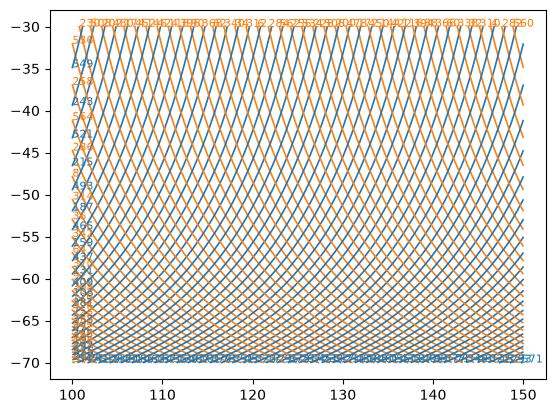

In [6]:
colors = {"asc": "tab:blue", "des": "tab:orange"}

ax = plt.subplot()

for idx, track in tracks.groupby('track'):
    # plt.plot(track['lon'], track['lat'], label=f"Track {idx}")
    direction = track["direction"].iloc[0]
    c=  colors.get(direction, "0.5")
    ax.plot(
        track["lon"],
        track["lat"],
        color=c,
        linewidth=1.2,
        label=direction,
    )
    plt.text(track["lon"].iloc[0], track["lat"].iloc[0], f"{idx}", fontsize=8, color=c)

#### Plot nominal tracks different missions, jason-3 in orange, Swot in blue

In [9]:
nominal = satpass.NominalTrack('j3')
tracks_j3 = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

nominal = satpass.NominalTrack('sw')
tracks_sw = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

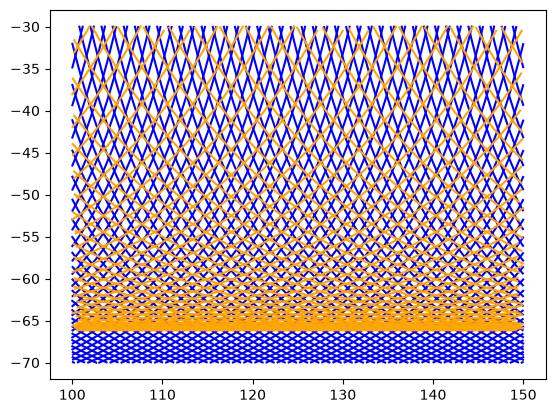

In [10]:
for idx, track in tracks_sw.groupby('track'):
    plt.plot(track['lon'], track['lat'], c = 'b')

for idx, track in tracks_j3.groupby('track'):
    plt.plot(track['lon'], track['lat'], c = 'orange')